In [1]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar

In [6]:
#ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

# Load datasets
DA_clims = []

for experiment in tqdm(experiments):
    ds = xr.open_dataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc')
    DA_clims.append((xr.where(ds['LWAA_tracked']>0,1,0).mean('time'))*100)
    ds.close()


100%|█████████████████████████████████████████████████████████████████████████| 4/4 [00:27<00:00,  6.93s/it]


In [7]:
DA_clims[0]

<xarray.DataArray 'LWAA_tracked' (lat: 61, lon: 240)> Size: 117kB
array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])
Coordinates:
  * lat      (lat) float64 488B 0.0 1.5 3.0 4.5 6.0 ... 84.0 85.5 87.0 88.5 90.0
  * lon      (lon) float64 2kB -180.0 -178.5 -177.0 -175.5 ... 175.5 177.0 178.5

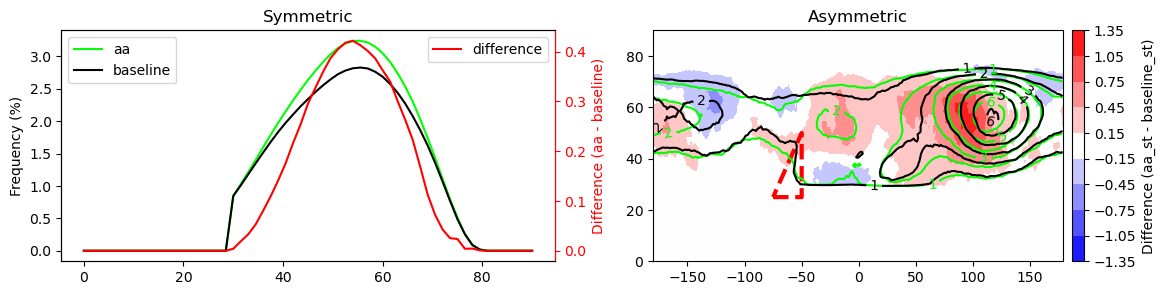

In [19]:
#create a 2 panels axis
fig, axs = plt.subplots(1, 2, figsize=(14, 3))

axs[0].set_title('Symmetric')

axs[0].plot(DA_clims[0].lat,DA_clims[1].mean('lon'),color='lime',label = 'aa')
axs[0].plot(DA_clims[0].lat,DA_clims[0].mean('lon'),color='black',label = 'baseline')
ax2 = axs[0].twinx()
ax2.spines['right'].set_color('red')
ax2.yaxis.label.set_color('red')
ax2.tick_params(axis='y', colors='red')
ax2.plot(DA_clims[0].lat,DA_clims[1].mean('lon')-DA_clims[0].mean('lon'),color='red',label = 'difference')
axs[0].legend(loc='upper left')
axs[0].set_ylabel('Frequency (%)', color='black')
ax2.legend(loc='upper right')
ax2.set_ylabel('Difference (aa - baseline)', color='red')


axs[1].set_title('Asymmetric')

#triangle coordinates
coords = [
    (-75.0, 25.0),  # Point A
    (-50.0, 25.0),  # Point B
    (-50.0, 50.0)   # Point C
]
# Unzip into separate lists of longitudes and latitudes, and close the triangle
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

cont_levels = np.arange(1,12,1)
levels = np.arange(-1.35,1.4,0.3)

axs[1].plot(lons, lats, linestyle='--',linewidth=3, color='red')
cs1 = axs[1].contour(DA_clims[0].lon, DA_clims[0].lat, DA_clims[3], cont_levels, colors='lime')
axs[1].clabel(cs1, fmt='%d', fontsize=10)
cs2 = axs[1].contour(DA_clims[0].lon, DA_clims[0].lat, DA_clims[2], cont_levels, colors='black')
axs[1].clabel(cs2, fmt='%d', fontsize=10)
axs[1].contourf(DA_clims[0].lon,DA_clims[0].lat,DA_clims[3]-DA_clims[2],levels,cmap='bwr')
cbar = plt.colorbar(axs[1].collections[-1], ax=axs[1], orientation='vertical', pad=0.02)
cbar.set_label('Difference (aa_st - baseline_st)')